# Time-Dependent Parameters

Astrophysical sources evolve: their magnetic field decays, their wind slows down, and they inject fewer particles as they age. In this tutorial, we will learn to give the operators parameters that **depend on time**, in two ways:

- As **plain callables**, functions that return the parameter at a given time. They work for any time dependence.
- As **separable parameters**, written as a formula with `TimeFactor`. They are optional, and make some simulations faster.

## 1. Setup

We consider a source at the center of the grid that injects electrons. Its wind carries them outwards while they diffuse and lose energy by synchrotron and inverse Compton emission. Let us compute the parameters of the operators as in the previous tutorials, for the conditions at the beginning of the simulation:

In [1]:
import time

import astropy.constants as const
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np

from saetass import Grid, Particle, Solver, State
from saetass import units as su
from saetass.cli import set_log_level
from saetass.utils.energy_losses import EnergyLossCalculator

set_log_level("WARNING")  # hide the messages of every simulation

E = np.logspace(0, 3, 101) * u.GeV
r = np.linspace(0.0, 40.0, 200) * u.pc
shape = (E.size, r.size)

# Energy losses in a uniform magnetic field and the photons of the CMB
B0 = np.full(r.size, 10.0) * u.uG
eps_grid = np.logspace(-9, -2, 120) * u.eV
x = (eps_grid / (const.k_B * 2.725 * u.K)).to_value(u.one)
dn_deps = 8 * np.pi * eps_grid**2 / (const.h * const.c) ** 3 / np.expm1(x)
dn_deps_2d = np.tile(dn_deps.to_value(u.cm**-3 / u.eV)[:, np.newaxis], r.size)

calc = EnergyLossCalculator(
    E_grid=E,
    r_grid=r,
    n_gas=np.full(r.size, 0.01) * u.cm**-3,
    particle=Particle.ELECTRON,
)
E_dot_synchrotron = calc.compute_synchrotron_losses(B_field=B0)
E_dot_ic = calc.compute_inverse_compton_losses(
    eps_grid=eps_grid, dn_deps=dn_deps_2d * u.cm**-3 / u.eV
)
# dp_dE converts energy losses to momentum losses
P_dot_synchrotron = E_dot_synchrotron * calc.dp_dE[:, np.newaxis]
P_dot_ic = E_dot_ic * calc.dp_dE[:, np.newaxis]

# Wind, diffusion and injection
p = calc.p_grid.to_value(su.MOMENTUM)
p_column = p[:, np.newaxis]
v0 = np.full(shape, 20.0) * u.km / u.s
D0 = np.broadcast_to(5.0 * p_column ** (1 / 3), shape) * u.pc**2 / u.Myr
Q0 = p_column**-2.0 * np.exp(-(r**2) / (2 * (2.0 * u.pc) ** 2)) * su.SOURCE_PSI_P

The power of the source and its magnetic field decay with time:

$$\frac{L(t)}{L_0} = e^{-t / t_L}, \qquad \frac{B(t)}{B_0} = \frac{1}{1 + t / t_B},$$

and every parameter changes with one of them. The injection scales as $L$, and the velocity of the wind as $L^{1/2}$ if its mass loss is constant. Synchrotron losses scale as $B^2$, and diffusion as $B^{-1/3}$ for Kolmogorov turbulence. Only the inverse Compton losses stay constant. We write these four factors as functions of the time, which is a Quantity:

In [2]:
t_L = 0.3 * u.Myr
t_B = 0.1 * u.Myr


def luminosity(t):
    # L / L_0
    return np.exp(-(t / t_L).to_value(u.one))


def wind_speed(t):
    # v / v_0
    return luminosity(t) ** 0.5


def field_squared(t):
    # (B / B_0)^2
    return (1.0 + (t / t_B).to_value(u.one)) ** -2


def diffusion(t):
    # D / D_0
    return field_squared(t) ** (-1 / 6)

## 2. Using plain callables

The simplest way is to give the operator a function instead of a Quantity. It takes the time and returns the whole parameter, both as Quantities. Sources are the only exception, since they also receive the coordinates `r` and `p`, as in the fourth tutorial:

In [3]:
def v_callable(t):
    return v0 * wind_speed(t)


def D_callable(t):
    return D0 * diffusion(t)


def P_dot_callable(t):
    return P_dot_synchrotron * field_squared(t) + P_dot_ic


def Q_callable(r, p, t):
    return Q0 * luminosity(t)


callables = {
    "advection": v_callable,
    "diffusion": D_callable,
    "loss": P_dot_callable,
    "source": Q_callable,
}

These are all the parameters that can depend on time:

| Operator | Parameter | Callable | Meaning |
|---|---|---|---|
| Advection | `v_centers` | `v(t)` | Velocity of the flow |
| Diffusion | `D_values` | `D(t)` | Diffusion coefficient |
| Diffusion | `psi_end` | `psi(t)` | Density at the outer boundary |
| Losses | `P_dot` | `P_dot(t)` | Momentum loss rate |
| Losses | `v_centers_physical` | `v(t)` | Velocity of the flow, for the adiabatic losses |
| Source | `source` | `Q(r, p, t)` | Injection rate |

## 3. Writing formulas with TimeFactor

Our parameters have something in common: they are sums of **fixed profiles** scaled by **functions of time**,

$$X(t, r, p) = \sum_k f_k(t)\, X_k(r, p).$$

SAETASS calls these parameters **separable**. To write one, mark the functions of time of its formula with `TimeFactor`:

In [4]:
from saetass import TimeFactor

v_separable = v0 * TimeFactor(wind_speed)
D_separable = D0 * TimeFactor(diffusion)
P_dot_separable = P_dot_synchrotron * TimeFactor(field_squared) + P_dot_ic
Q_separable = Q0 * TimeFactor(luminosity)

separables = {
    "advection": v_separable,
    "diffusion": D_separable,
    "loss": P_dot_separable,
    "source": Q_separable,
}
print(type(P_dot_separable))

<class 'saetass.parameters.Separable'>


The result is a `Separable` object, which every parameter of the table accepts. It can be added to other parameters and to Quantities, which are constant terms such as `P_dot_ic`, and multiplied by numbers. The profiles broadcast to a common shape, as those of NumPy do.

Calling a separable parameter gives its value at a time, which is useful to check it:

In [5]:
t = 0.2 * u.Myr
print("Same losses:", u.allclose(P_dot_separable(t), P_dot_callable(t)))

Same losses: True


### Writing the profiles and the factors

`Separable` can also be created directly from its profiles and their factors, which is convenient when there are many of them. A factor can also be a number, for constant terms:

In [6]:
from saetass import Separable

P_dot_direct = Separable([P_dot_synchrotron, P_dot_ic], [field_squared, 1.0])
print("Same losses:", u.allclose(P_dot_direct(t), P_dot_callable(t)))

Same losses: True


### Scaling the loss mechanisms

For energy losses we do not need to write the formula at all. The `EnergyLossCalculator` knows the profile of each mechanism, so `get_momentum_loss_rate()` returns the separable loss rate if we give it the time factors of the mechanisms that change. Those without a factor, such as inverse Compton here, are constant:

In [7]:
P_dot_calculator = calc.get_momentum_loss_rate(
    time_factors={"synchrotron": field_squared}
)
print("Same losses:", u.allclose(P_dot_calculator(t), P_dot_callable(t)))

Same losses: True


## 4. Running the simulation

Both forms are given to the `Solver` in the same way. Let us simulate 0.5 Myr with constant parameters, with the callables and with the separable parameters:

In [8]:
options = {"limiter": "minmod", "order": 2, "cfl": 0.8}


def run(problem_type, parameters, num_timesteps=100):
    # Final distribution, and seconds taken by the simulation
    t_grid = np.linspace(0.0, 0.5, num_timesteps + 1) * u.Myr
    grid = Grid(r_centers=r, p_centers=calc.p_grid, t_grid=t_grid)
    operator_params = {
        "advection": {
            "v_centers": parameters["advection"],
            "inflow_value_U": 0.0 * su.AREA * su.PSI_P,
            **options,
        },
        "diffusion": {"D_values": parameters["diffusion"]},
        "loss": {
            "P_dot": parameters["loss"],
            "inflow_value_U": 0.0 * su.MOMENTUM * su.PSI_P,
            **options,
        },
        "source": {"source": parameters["source"]},
    }
    operators = problem_type.split("-")
    solver = Solver(
        state=State(grid, psi_p=np.zeros(shape) * su.PSI_P, particle=Particle.ELECTRON),
        problem_type=problem_type,
        operator_params={name: operator_params[name] for name in operators},
        quiet=True,
    )
    start = time.perf_counter()
    psi = solver.run().psi_p.to_value(su.PSI_P)
    return psi.copy(), time.perf_counter() - start


constants = {
    "advection": v0,
    "diffusion": D0,
    "loss": P_dot_synchrotron + P_dot_ic,
    "source": Q0,
}
cases = {"constant": constants, "callables": callables, "separables": separables}
problem = "advection-diffusion-loss-source"
results = {}
for name, parameters in cases.items():
    run(problem, parameters)  # the first run may compile the numerical kernels
    results[name], seconds = run(problem, parameters)
    print(f"{name:<11} {seconds:.2f} s")

difference = np.abs(results["separables"] - results["callables"]).max()
print(f"Relative difference: {difference / results['callables'].max():.0e}")

constant    0.05 s


callables   0.09 s
separables  0.08 s
Relative difference: 5e-16


Callables and separable parameters give the same distribution, to rounding error, so the choice between them is only a matter of convenience and speed, as we will see in the next section. Let us first see how the evolution of the source changes the electrons, with their spectrum at two radii:

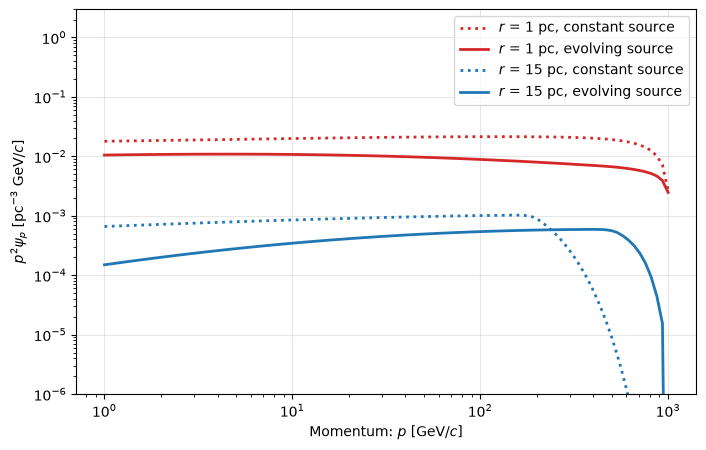

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
for radius, color in [(1.0, "#d62728"), (15.0, "#1f77b4")]:
    i = np.argmin(np.abs(r.value - radius))
    for name, ls in [("constant", ":"), ("separables", "-")]:
        label = "constant" if name == "constant" else "evolving"
        ax.loglog(
            p,
            p**2 * results[name][:, i],
            color=color,
            ls=ls,
            lw=2,
            label=f"$r$ = {radius:.0f} pc, {label} source",
        )
ax.set_xlabel(r"Momentum: $p$ [GeV/$c$]")
ax.set_ylabel(r"$p^2 \psi_p$ [pc$^{-3}$ GeV/$c$]")
ax.set_ylim(1e-6, 3e0)
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

The source injects fewer particles as it ages, so the evolving spectra are lower at most momenta. The highest momenta at 15 pc are the exception: the electrons that get there have lost less energy, since the magnetic field has decayed, and diffuse faster.

## 5. Choosing between callables and separable parameters

Advection and losses divide every time step into **CFL sub-cycles** when the particles cross several cells in it. Let us run each operator on its own, with steps ten times longer, so that these two need several sub-cycles per step:

In [10]:
for operator in ("advection", "diffusion", "loss", "source"):
    seconds = {
        name: min(run(operator, cases[name], 10)[1] for _ in range(5))
        for name in ("callables", "separables")
    }
    print(
        f"{operator:<10} callable {1e3 * seconds['callables']:7.1f} ms, "
        f"separable {1e3 * seconds['separables']:7.1f} ms"
    )

advection  callable     5.6 ms, separable     2.6 ms
diffusion  callable     1.8 ms, separable     1.8 ms
loss       callable     4.1 ms, separable     2.0 ms
source     callable     0.3 ms, separable     0.2 ms


With a callable, Python evaluates the parameter on the whole grid at **every sub-cycle**. With a separable parameter, it only evaluates the factors, which are numbers, and a single compiled call advances all the sub-cycles of the step. The gain grows with the number of sub-cycles, and there is little or none without them. Diffusion and sources evaluate their parameters once per step, so both forms take the same time.

When several operators are combined, the splitting between them asks for short time steps, with few sub-cycles, unless the grid is fine. This is why our simulation gained little.

| Case | Use |
|---|---|
| Losses or advection with many sub-cycles per step, such as the losses of electrons on a fine momentum grid | Separable parameters |
| Any other parameter | Whichever is easier to write |
| A time dependence that is not a sum of profiles times factors, such as a moving shock | A plain callable |

Whatever their form, parameters must change little during a time step. The [diagnostics](07_simulation_diagnostics.ipynb) evaluate them at several times to find the worst case, and report how many sub-cycles each operator needs, as `cfl_subcycles`.

## Summary

In this tutorial, you learned:
1. Which parameters of the operators can **depend on time**.
2. How to give them as **plain callables**, for any time dependence.
3. How to write them as **separable parameters**, with `TimeFactor`, `Separable` or the time factors of the `EnergyLossCalculator`.
4. When separable parameters make a simulation **faster**.